# 03 · Real rainfall: four generators judged on held-out winters, and Storm Desmond

**The question.** Can a generator that produces realistic-looking rainfall fields also assign the
right probabilities to the most extreme days, including one more severe than any it was trained on?

**Design: a 2 × 2 comparison.** Every generator maps rainfall to normal scores with per-cell
margins, models the spatial dependence of those scores, and maps samples back to millimetres.

| | empirical margins (cannot exceed the training maximum) | EVT margins (GPD tail above the 95th percentile) |
|---|---|---|
| **Gaussian copula** | simplest model | classical spatial statistics |
| **VAE** (convolutional, latent Gaussian mixture) | "learn the data distribution" | hybrid: neural dependence, EVT tails |

Comparing rows isolates the dependence model; comparing columns isolates the margins.

**Leakage rules.** Margins, normal scores, the copula and the VAE use **training** winters only.
**Validation** winters are used only for VAE early stopping and choosing the latent mixture size.
**Test** winters, including Storm Desmond's 2015/16, are used only here, after all fitting.

**Baselines.** Twelve test winters are a small sample of the climate. So every comparison with the
test winters is also made for the **training winters themselves**: the score of a model that
reproduced its training data perfectly. This baseline is a reference point, not a lower bound:
a model can match the test winters better than its own training data does, by chance.

To rerun the experiment (about 1.5 hours on a 2-core CPU), set `RUN = True`.

In [1]:
# Setup: works locally (from the repository root or notebooks/) and on Google Colab
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("rainfall-extremes-pilot").exists():
    !git clone -q https://github.com/RidhimaGupta4/rainfall-extremes-pilot.git
    os.chdir("rainfall-extremes-pilot")
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "cumbria_winter_rainfall_5km.nc"
RESULTS = Path(os.environ.get("RAINPILOT_RESULTS", ROOT / "results"))
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

In [2]:
import json, subprocess, pandas as pd
from scipy import stats
RUN = False
if RUN:
    subprocess.run([sys.executable, str(ROOT / "experiments/cumbria_experiment.py")], check=True)
res = json.loads((RESULTS / "cumbria_experiment.json").read_text())
NAMES = ['Gaussian copula + empirical margins', 'Gaussian copula + EVT margins', 'VAE + empirical margins', 'VAE + EVT margins']
COL = {"Gaussian copula + empirical margins": "#9ecae1", "Gaussian copula + EVT margins": "#0072B2", "VAE + empirical margins": "#fdae6b", "VAE + EVT margins": "#D55E00"}
EVT = ["Gaussian copula + EVT margins", "VAE + EVT margins"]
ref, fl, ds = res["reference"], res["floors"], res["desmond"]
print("days train / val / test:", res["split"]["n_days"])
print(f"fitted shared GPD shape xi = {res['fitted']['xi']:.3f}")
print("VAE runs:", [(v["seed"], v["best_epoch"], v["latent_components"]) for v in res["vae"]], "(seed, best epoch, mixture size)")
def vals(name, f):
    return np.array([f(r) for r in res["models"][name]])
def fmt(v, d=3, sign=False):
    f = f"{{:{'+' if sign else ''}.{d}f}}"
    return f.format(v.mean()) + ("" if len(v) == 1 else f" ({f.format(v.min())} to {f.format(v.max())})")

days train / val / test: [7107, 2370, 2187]
fitted shared GPD shape xi = 0.077
VAE runs: [(0, 94, 16), (1, 78, 16), (2, 88, 8)] (seed, best epoch, mixture size)


## 1 · The baseline: how different are the test winters from the training winters?

If a model reproduced the training winters exactly, how would its quantiles compare with the test
winters? The bracket is a 95% block-bootstrap interval over test winters: the range of scores such
a perfect copy could get from test-winter sampling alone.

In [3]:
TL = {"1": "single cell", "2": "10 km", "4": "20 km", "8": "40 km", "16": "80 km box"}
rows = []
for k, kn in TL.items():
    r = {"scale": kn}
    for p in ["0.99", "0.999"]:
        lo, hi = fl["log_ratio_train_vs_test_ci"][k][p]
        r[f"train vs test, 1 in {round(1/(1-float(p)))}"] = f"{fl['log_ratio_train_vs_test'][k][p]:+.3f} ({lo:+.2f} to {hi:+.2f})"
        r[f"val vs test, 1 in {round(1/(1-float(p)))}"] = f"{fl['log_ratio_val_vs_test'][k][p]:+.3f}"
    rows.append(r)
pd.DataFrame(rows).set_index("scale")

,"train vs test, 1 in 100","val vs test, 1 in 100","train vs test, 1 in 1000","val vs test, 1 in 1000"
scale,,,,
single cell,-0.058 (-0.17 to +0.07),-0.077,-0.056 (-0.29 to +0.17),-0.164
10 km,-0.064 (-0.18 to +0.07),-0.082,-0.049 (-0.29 to +0.18),-0.160
20 km,-0.068 (-0.17 to +0.07),-0.087,-0.045 (-0.30 to +0.19),-0.177
40 km,-0.051 (-0.16 to +0.06),-0.079,-0.065 (-0.37 to +0.18),-0.173
80 km box,-0.096 (-0.20 to +0.03),-0.096,-0.101 (-0.44 to +0.23),-0.135


## 2 · Tail quantiles, against the test winters and against the training winters

Below, the 1-in-100-day and 1-in-1,000-day quantiles of rainfall averaged over areas from 5 km to
80 km across. The **dashed line** is the baseline (the training winters themselves) and the **grey
band** its test-sampling interval. A model on the dashed line reproduces its training climate;
the distance between the dashed line and zero is a property of the test winters, not of any model.

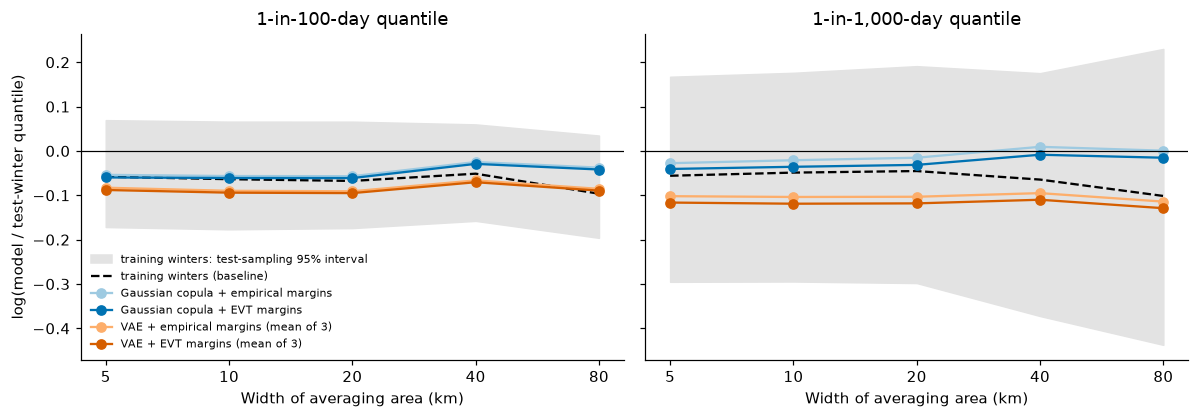

In [4]:
tiles = list(TL); km = [5, 10, 20, 40, 80]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, p in zip(axes, ["0.99", "0.999"]):
    f0 = np.array([fl["log_ratio_train_vs_test"][k][p] for k in tiles])
    ci = np.array([fl["log_ratio_train_vs_test_ci"][k][p] for k in tiles])
    ax.fill_between(km, ci[:, 0], ci[:, 1], color="#e3e3e3", label="training winters: test-sampling 95% interval")
    ax.plot(km, f0, "k--", lw=1.5, label="training winters (baseline)")
    for name in NAMES:
        v = np.array([[m["log_ratio_vs_test"][k][p] for k in tiles] for m in res["models"][name]])
        ax.plot(km, v.mean(0), "o-", color=COL[name], label=name + ("" if len(v) == 1 else " (mean of 3)"))
    ax.axhline(0, color="black", lw=0.8); ax.set_xscale("log", base=2); ax.set_xticks(km); ax.set_xticklabels(km)
    ax.set_xlabel("Width of averaging area (km)")
    ax.set_title(f"1-in-{round(1/(1-float(p))):,}-day quantile")
axes[0].set_ylabel("log(model / test-winter quantile)"); axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "areal_quantiles.png", bbox_inches="tight"); plt.show()

In [5]:
# EVT generators: bias against the test winters and against the training winters, and the
# difference between the two generators (which does not depend on the reference at all).
rows = []
for k in ["1", "4", "16"]:
    for p in ["0.99", "0.999"]:
        r = {"scale": TL[k], "level": f"1 in {round(1/(1-float(p))):,}"}
        for name in EVT:
            short = name.split(" + ")[0]
            r[f"{short} vs test"] = fmt(vals(name, lambda m: m["log_ratio_vs_test"][k][p]), 3, True)
            r[f"{short} vs train"] = fmt(vals(name, lambda m: m["log_ratio_vs_train"][k][p]), 3, True)
        g = vals(EVT[0], lambda m: m["log_ratio_vs_test"][k][p])[0]
        r["copula minus VAE"] = fmt(g - vals(EVT[1], lambda m: m["log_ratio_vs_test"][k][p]), 3, True)
        rows.append(r)
quant_tab = pd.DataFrame(rows).set_index(["scale", "level"])
quant_tab

Gaussian copula vs test Gaussian copula vs train  \
scale       level                                                         
single cell 1 in 100                    -0.060                   -0.002   
            1 in 1,000                  -0.041                   +0.015   
20 km       1 in 100                    -0.061                   +0.006   
            1 in 1,000                  -0.031                   +0.014   
80 km box   1 in 100                    -0.042                   +0.055   
            1 in 1,000                  -0.015                   +0.086   

                                      VAE vs test               VAE vs train  \
scale       level                                                              
single cell 1 in 100    -0.088 (-0.105 to -0.079)  -0.030 (-0.047 to -0.021)   
            1 in 1,000  -0.116 (-0.136 to -0.088)  -0.060 (-0.080 to -0.032)   
20 km       1 in 100    -0.095 (-0.111 to -0.087)  -0.027 (-0.043 to -0.019)   
            1 in 1,000  -0.118 (-0.138 to -0.089)  -0.073 (-0.093 to -0.044)   
80 km box   1 in 100    -0.089 (-0.100 to -0.083)  +0.007 (-0.004 to +0.013)   
            1 in 1,000  -0.129 (-0.152 to -0.094)  -0.028 (-0.050 to +0.008)   

                                 copula minus VAE  
scale       level                                  
single cell 1 in 100    +0.028 (+0.019 to +0.045)  
            1 in 1,000  +0.076 (+0.048 to +0.096)  
20 km       1 in 100    +0.034 (+0.026 to +0.050)  
            1 in 1,000  +0.087 (+0.058 to +0.107)  
80 km box   1 in 100    +0.048 (+0.042 to +0.059)  
            1 in 1,000  +0.114 (+0.078 to +0.136)

**Calibration at one day in 100.** The share of test days above each generator's per-cell
1-in-100-day level, against the same share for the training winters' own level (the baseline). The
interval is a block bootstrap over test winters.

In [6]:
lo, hi = fl["test_exceedance_of_train_quantile_ci"]["0.99"]
byw = np.array(fl["test_exceedance_by_winter"]["0.99"])
print(f"baseline (training winters' own 1-in-100 level): {100*fl['test_exceedance_of_train_quantile']['0.99']:.2f}% "
      f"(95% interval {100*lo:.2f}% to {100*hi:.2f}%; single test winters range {100*byw.min():.2f}% to {100*byw.max():.2f}%)")
for name in NAMES:
    v = 100 * vals(name, lambda m: m["test_exceedance_of_model_quantile"]["0.99"])
    print(f"  {name:38s} {fmt(v, 2)}%")

baseline (training winters' own 1-in-100 level): 1.26% (95% interval 0.78% to 1.81%; single test winters range 0.26% to 3.40%)
  Gaussian copula + empirical margins    1.24%
  Gaussian copula + EVT margins          1.26%
  VAE + empirical margins                1.37 (1.33 to 1.45)%
  VAE + EVT margins                      1.39 (1.35 to 1.46)%


## 3 · Realism: ordinary rainfall and joint extremes, against the baseline

Errors against the test winters for the spatial correlation of log(1 + rainfall), the wet-area
fraction (quantiles of the share of cells above 1 mm), the mean rainfall map (relative error), and
chi(u) at u = 0.95 and 0.98. The baseline rows give the same errors for the training and validation
winters themselves: the error that comes from the test winters being a different sample. A model
can fall below it by chance.

In [7]:
MET = [("corr. error", "corr_log_abs_error", None), ("wet-area error", "wet_fraction_abs_error", None),
       ("mean-map error", "cell_mean_rel_error", None), ("chi(0.95) error", "chi_abs_error", "0.95"),
       ("chi(0.98) error", "chi_abs_error", "0.98")]
def get(m, key, u):
    return m[key][u] if u else m[key]
rows = []
for name in NAMES:
    rows.append({"": name, **{lab: fmt(vals(name, lambda m: get(m, key, u)), 3) for lab, key, u in MET}})
for which in ["train", "val"]:
    b = fl[f"bulk_{which}_vs_test"]
    rows.append({"": f"baseline: {'training' if which == 'train' else 'validation'} winters",
                 **{lab: f"{(fl[f'chi_abs_error_{which}_vs_test'][u] if u else b[key]):.3f}" for lab, key, u in MET}})
realism_tab = pd.DataFrame(rows).set_index("")
realism_tab

,corr. error,wet-area error,mean-map error,chi(0.95) error,chi(0.98) error
,,,,,
Gaussian copula + empirical margins,0.018,0.023,0.019,0.019,0.080
Gaussian copula + EVT margins,0.018,0.023,0.019,0.019,0.080
VAE + empirical margins,0.010 (0.009 to 0.012),0.021 (0.020 to 0.022),0.022 (0.021 to 0.024),0.017 (0.009 to 0.028),0.027 (0.019 to 0.036)
VAE + EVT margins,0.010 (0.009 to 0.012),0.021 (0.020 to 0.022),0.022 (0.020 to 0.024),0.017 (0.009 to 0.028),0.027 (0.019 to 0.036)
baseline: training winters,0.006,0.019,0.020,0.021,0.014
baseline: validation winters,0.006,0.008,0.016,0.048,0.027


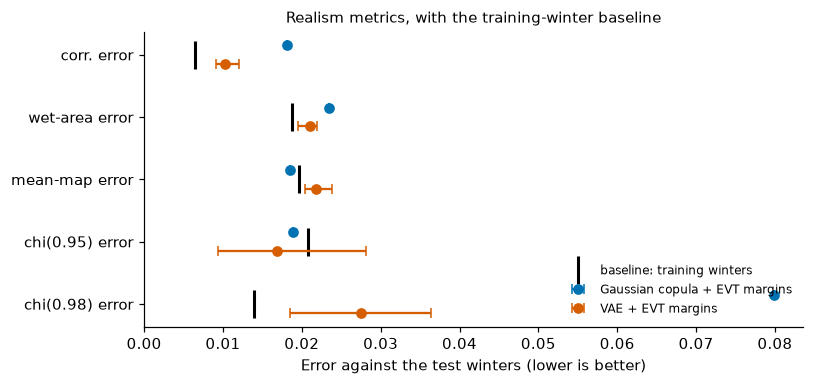

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
labs = [m[0] for m in MET]
for j, (lab, key, u) in enumerate(MET):
    f_tr = fl["chi_abs_error_train_vs_test"][u] if u else fl["bulk_train_vs_test"][key]
    ax.plot([f_tr], [j], "k|", ms=18, mew=2, label="baseline: training winters" if j == 0 else None)
    for i, name in enumerate(EVT):
        v = vals(name, lambda m: get(m, key, u))
        ax.errorbar(v.mean(), j + (0.15 if i else -0.15), xerr=[[v.mean() - v.min()], [v.max() - v.mean()]],
                    fmt="o", color=COL[name], capsize=3, label=name if j == 0 else None)
ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs); ax.invert_yaxis()
ax.set_xlabel("Error against the test winters (lower is better)"); ax.set_xlim(left=0)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Realism metrics, with the training-winter baseline", fontsize=10)
plt.tight_layout(); plt.savefig(FIGS / "realism_metrics.png", bbox_inches="tight"); plt.show()

## 4 · Joint extremes in space: chi(u) against distance

Cell pairs are grouped into contiguous distance bands, labelled by the band centre. The grey band
is a pointwise 95% block-bootstrap interval over test winters (10 bands, so a single excursion is
not strong evidence by itself). The dashed line is chi for the training winters.

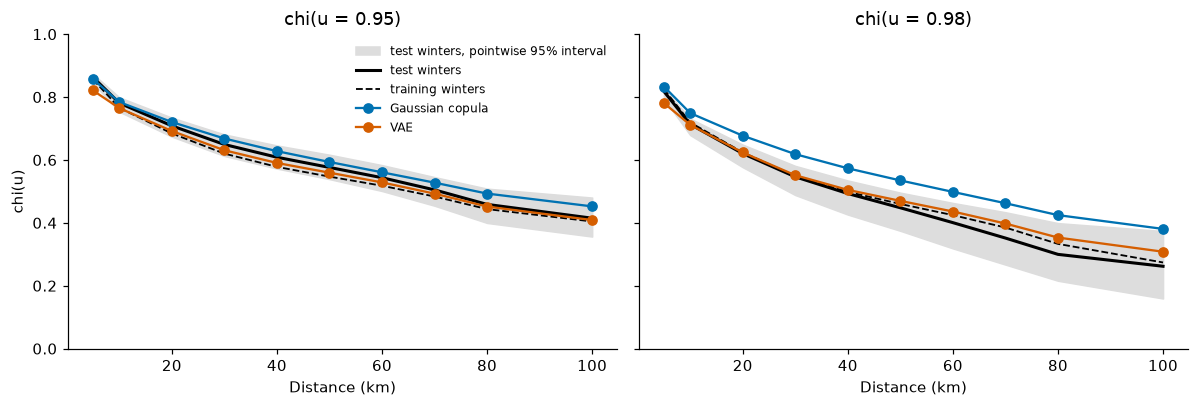

Gaussian copula + EVT margins    u=0.95: above test interval in 0/10 bands, below in 0/10
Gaussian copula + EVT margins    u=0.98: above test interval in 10/10 bands, below in 0/10
VAE + EVT margins                u=0.95: above test interval in 0/10 bands, below in 1/10
VAE + EVT margins                u=0.98: above test interval in 0/10 bands, below in 1/10


In [9]:
from rainpilot.diagnostics import DIST_BINS as bins
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, u in zip(axes, ["0.95", "0.98"]):
    lo, hi = np.array(ref["chi_ci"][u])
    ax.fill_between(bins, lo, hi, color="#dddddd", label="test winters, pointwise 95% interval")
    ax.plot(bins, ref["chi"][u], "k-", lw=2, label="test winters")
    ax.plot(bins, fl["chi_train"][u], "k--", lw=1.2, label="training winters")
    for name in EVT:
        v = np.array([m["chi"][u] for m in res["models"][name]])
        ax.plot(bins, v.mean(0), "o-", color=COL[name], label=name.split(" + ")[0])
    ax.set_title(f"chi(u = {u})"); ax.set_xlabel("Distance (km)"); ax.set_ylim(0, 1)
axes[0].set_ylabel("chi(u)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "chi_cumbria.png", bbox_inches="tight"); plt.show()
for name in EVT:
    for u in ["0.95", "0.98"]:
        v = np.array([m["chi"][u] for m in res["models"][name]]).mean(0)
        lo, hi = np.array(ref["chi_ci"][u])
        print(f"{name:32s} u={u}: above test interval in {int((v > hi).sum())}/10 bands, below in {int((v < lo).sum())}/10")

## 5 · Does the dependence model produce extreme normal scores often enough?

EVT margins can only extrapolate if the dependence model produces extreme normal scores. The
ratio below is the share of generated normal scores above the 1-in-100, 1-in-1,000 and
1-in-10,000 levels, divided by its target (1 = correct). Generated scores are strongly dependent
across cells, so Monte Carlo noise is much larger than for independent draws. The noise reference
is the range over 20 independent samples from the Gaussian copula, whose scores are exactly normal.

In [10]:
nz = res["normal_score_noise"]
for p in ["0.99", "0.999", "0.9999"]:
    lo, hi = nz["range"][p]
    print(f"1 in {round(1/(1-float(p))):>6,}: noise reference {lo:.2f} to {hi:.2f} | " + " | ".join(
        f"{n.split(' + ')[0]}: " + ", ".join(f"{v:.2f}" for v in vals(n, lambda m: m['normal_score_exceedance_ratio'][p]))
        for n in EVT))

1 in    100: noise reference 0.95 to 1.02 | Gaussian copula: 1.02 | VAE: 0.92, 0.92, 0.85
1 in  1,000: noise reference 0.92 to 1.17 | Gaussian copula: 1.07 | VAE: 0.60, 0.74, 0.59
1 in 10,000: noise reference 0.79 to 1.31 | Gaussian copula: 1.19 | VAE: 0.31, 0.69, 0.45


## 6 · Stress test: how likely was Storm Desmond?

For each generator: the daily probability of a day at least as extreme as 5 December 2015, as
(a) a box mean of 83.5 mm or more, and (b) any cell with 254.8 mm or more, converted to an average
number of winters between such days (182.25 days per October–March winter, ignoring clustering).
None of the generators saw Desmond. The training data's largest values were 81.3 mm (box mean,
January 2005) and 245.2 mm (one cell).

**Two kinds of uncertainty are shown.**
* *Monte Carlo*: an exact Poisson interval for the number of hits.
* *Tail (margin) uncertainty*: the EVT margins are refitted on 100 block-bootstrap resamples of
  the training winters and applied to the **same** generated normal scores (2 million for the
  copula, 6 million pooled over three VAE seeds). The dependence models are held fixed, so these
  intervals do not include uncertainty in the copula's correlations or in VAE training.

Empirical margins cannot produce a wettest cell above the training maximum (245.2 mm), so their
"never" for the cell is guaranteed by construction, not an empirical finding.

In [11]:
D = 182.25
def rp(h, n):
    return np.inf if h == 0 else n / (h * D)
def poisson_rp(h, n):
    lo = stats.chi2.ppf(0.025, 2 * h) / 2 if h > 0 else 0.0
    hi = stats.chi2.ppf(0.975, 2 * h + 2) / 2
    return n / (hi * D), (np.inf if lo == 0 else n / (lo * D))
def s_rp(v):
    return "never" if np.isinf(v) else f"{v:.0f}"
rows = []
for name in NAMES:
    d = [m["desmond"] for m in res["models"][name]]
    n = sum(x["n"] for x in d)
    r = {"model": name, "generated days": f"{n:,}"}
    for kind in ["box", "cell"]:
        h = sum(x[f"hits_{kind}"] for x in d)
        a, b = poisson_rp(h, n)
        r[f"{kind}: hits"] = h
        r[f"{kind}: return period (winters)"] = s_rp(rp(h, n))
        r[f"{kind}: Monte Carlo 95%"] = f"{s_rp(a)} to {s_rp(b)}"
        bt = res["bootstrap_train"]["models"].get(name)
        if bt:
            ps = np.array([x[f"p_{kind}"] for x in bt])
            p_lo, p_hi = np.percentile(ps, [2.5, 97.5])
            inv = lambda q: np.inf if q == 0 else 1 / (q * D)     # return period falls as p rises
            r[f"{kind}: tail-uncertainty 95%"] = f"{s_rp(inv(p_hi))} to {s_rp(inv(p_lo))}"
        else:
            r[f"{kind}: tail-uncertainty 95%"] = "n/a"
        if len(d) > 1:
            r[f"{kind}: per VAE seed"] = ", ".join(s_rp(rp(x[f"hits_{kind}"], x["n"])) for x in d)
    rows.append(r)
desmond_tab = pd.DataFrame(rows).set_index("model").T
desmond_tab

model,Gaussian copula + empirical margins,Gaussian copula + EVT margins,VAE + empirical margins,VAE + EVT margins
generated days,"2,000,000","2,000,000","6,000,000","6,000,000"
box: hits,133,170,86,148
box: return period (winters),83,65,383,222
box: Monte Carlo 95%,70 to 99,56 to 75,310 to 479,189 to 263
box: tail-uncertainty 95%,n/a,34 to 175,n/a,115 to 806
cell: hits,0,171,0,164
cell: return period (winters),never,64,never,201
cell: Monte Carlo 95%,2975 to never,55 to 75,8925 to never,172 to 235
cell: tail-uncertainty 95%,n/a,25 to 282,n/a,57 to 1244
box: per VAE seed,NaN,NaN,"646, 200, 784","392, 114, 457"


In [12]:
xi_b = np.array(res["bootstrap_train"]["xi"])
print(f"shared xi: {res['fitted']['xi']:.3f}; bootstrap 95% interval over training winters: "
      f"{np.percentile(xi_b, 2.5):.3f} to {np.percentile(xi_b, 97.5):.3f}")
for name in EVT:
    h = np.array([x["hits_cell"] for x in res["bootstrap_train"]["models"][name]])
    print(f"{name}: hits (cell) per bootstrap replicate, median {np.median(h):.0f}, range {h.min()} to {h.max()}")

shared xi: 0.077; bootstrap 95% interval over training winters: 0.018 to 0.122
Gaussian copula + EVT margins: hits (cell) per bootstrap replicate, median 145, range 33 to 553
VAE + EVT margins: hits (cell) per bootstrap replicate, median 146, range 20 to 794


### Storm structure at Desmond's severity, and at each generator's own extreme

**Top row:** for a like-for-like comparison of *structure*, each generator's day whose box mean
is closest to Desmond's 83.5 mm, from 400,000 draws (seed 0). **Bottom row:** each generator's
single most extreme box-mean day from the same 400,000 draws. That row shows how each generator
extrapolates, not a typical event. Fields come from `experiments/desmond_analogues.py`. One
colour scale is used throughout. These are single samples, so the figure is illustrative only.

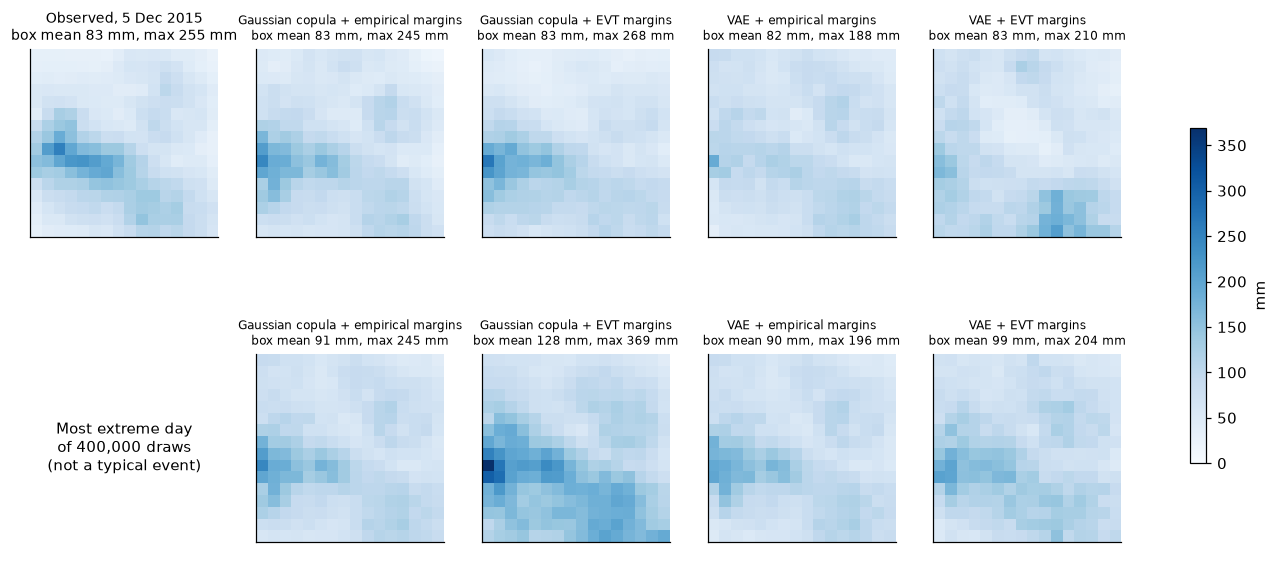

In [13]:
an = json.loads((RESULTS / "desmond_analogues.json").read_text())
obs = np.array(ds["field"])
vmax = max(obs.max(), max(np.max(v["most_extreme"]) for v in an["models"].values()))
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
for row in range(2):
    ax = axes[row, 0]
    if row == 0:
        im = ax.imshow(obs, origin="lower", cmap="Blues", vmin=0, vmax=vmax)
        ax.set_title(f"Observed, 5 Dec 2015\nbox mean {obs.mean():.0f} mm, max {obs.max():.0f} mm", fontsize=9)
    else:
        ax.axis("off")
        ax.text(0.5, 0.5, f"Most extreme day\nof {an['n_draws']:,} draws\n(not a typical event)",
                ha="center", va="center", fontsize=10)
    for ax, name in zip(axes[row, 1:], NAMES):
        f = np.array(an["models"][name]["analogue" if row == 0 else "most_extreme"])
        ax.imshow(f, origin="lower", cmap="Blues", vmin=0, vmax=vmax)
        ax.set_title(f"{name}\nbox mean {f.mean():.0f} mm, max {f.max():.0f} mm", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.6, label="mm")
plt.savefig(FIGS / "desmond_vs_generated.png", bbox_inches="tight"); plt.show()

Two simple checks on the analogues, against the 20 wettest training days (box mean): the
correlation of each field with the observed Desmond field, and a roughness index (mean absolute
difference between neighbouring cells, divided by the field mean). If the analogues fall inside
the range of ordinary large training days, the figure does not distinguish the generators.

In [14]:
from rainpilot.data import load, interleaved_split
x_all, t_all, w_all, _ = load(DATA)
xtr = x_all[interleaved_split(w_all).train]
def rough(f):
    f = np.asarray(f)
    return (np.abs(np.diff(f, axis=0)).mean() + np.abs(np.diff(f, axis=1)).mean()) / 2 / f.mean()
def corr(f):
    return np.corrcoef(np.ravel(f), obs.ravel())[0, 1]
top = xtr[np.argsort(xtr.mean((1, 2)))[-20:]]
rt, ct = np.array([rough(f) for f in top]), np.array([corr(f) for f in top])
print(f"observed Desmond: roughness {rough(obs):.3f}")
print(f"20 wettest training days: roughness {rt.min():.3f} to {rt.max():.3f} (median {np.median(rt):.3f}); "
      f"correlation with Desmond {ct.min():.2f} to {ct.max():.2f} (median {np.median(ct):.2f})")
for name in NAMES:
    f = an["models"][name]["analogue"]
    print(f"  analogue, {name:38s} roughness {rough(f):.3f}, correlation with Desmond {corr(f):.2f}")

observed Desmond: roughness 0.181
20 wettest training days: roughness 0.115 to 0.184 (median 0.142); correlation with Desmond 0.37 to 0.91 (median 0.82)
  analogue, Gaussian copula + empirical margins    roughness 0.160, correlation with Desmond 0.80
  analogue, Gaussian copula + EVT margins          roughness 0.137, correlation with Desmond 0.81
  analogue, VAE + empirical margins                roughness 0.130, correlation with Desmond 0.73
  analogue, VAE + EVT margins                      roughness 0.154, correlation with Desmond 0.40


## Reading the results

The interpretation below is written from the run stored in `results/`. If you rerun the
experiment, check that it still holds.

**1. The test winters are wetter than the training winters, by about as much as the models differ.**
Against the 12 test winters, the training winters' own quantiles are about 6% lower for single
cells (log ratio −0.058 at one day in 100) and about 9% lower for the 80 km box (−0.096). A model that copied
its training data perfectly would therefore look "too low" by that amount. The validation winters
differ from the test winters by a similar amount (−0.08 to −0.18). From test-winter sampling alone,
such a perfect copy could score anywhere from about −0.17 to +0.07 (single cells, one day in 100)
or −0.30 to +0.17 (one day in 1,000). Every generator lies inside these ranges, so **the test
winters cannot rank the generators' tails.** Judged against the test winters alone, the Gaussian
copula would look better at every scale. That conclusion would be an artefact of the test sample.

**2. Against the training winters, the answer depends on scale.** This compares each generator
with the data it was fitted to (EVT margins; VAE values are the range over 3 seeds):
* **Single cells:** the Gaussian copula matches its training climate (−0.002 at one day in 100,
  +0.015 at one in 1,000). The VAE is 2–5% too low (−0.02 to −0.05) and 3–8% too low (−0.03 to −0.08).
* **80 km box:** the Gaussian copula is **too high**, by about 6% (+0.055) and 9% (+0.086). The VAE is
  close (−0.004 to +0.013, and −0.05 to +0.01).

So the copula is better for single cells and the VAE better for area averages. The difference
between the two generators does not depend on any reference: at one day in 100 the copula's box
quantile exceeds the VAE's by 4–6% (+0.042 to +0.059 on the log scale, depending on the VAE seed).

**3. Calibration at one day in 100 does not separate the generators either.** Test days exceed the
training winters' own per-cell 1-in-100 level on 1.26% of days (95% interval 0.78–1.81%; single
test winters range from 0.26% to 3.4%). The Gaussian copula gives 1.26% and the VAE 1.35–1.46%:
all inside the test-sampling interval.

**4. Realism.** Against the baseline (training winters versus test winters):
* **Spatial correlation:** the VAE is closer (error 0.009–0.012 against 0.018; baseline 0.006).
* **Joint extremes, chi(0.98):** the VAE is much closer (0.019–0.036 against 0.080; baseline 0.014).
  The Gaussian copula **overstates** joint extremes: its chi(0.98) lies above the test winters'
  pointwise 95% interval in all 10 distance bands, and the training winters' chi is close to the test
  winters' (error 0.014), so this is a property of the model, not of the test sample. It is
  consistent with the copula overstating area-averaged quantiles in point 2. At u = 0.95 the two
  generators are indistinguishable (0.019 against 0.009–0.028; baseline 0.021).
* **At 5 km the VAE is too weak:** its chi lies below the test interval in the 5 km band for every
  seed, at both levels. This is consistent with its independent per-pixel decoder noise, which
  makes neighbouring cells less alike; that explanation is not tested here.
* **Wet-area fraction and mean rainfall map:** both generators are close to the baseline (wet area 0.023
  against 0.020–0.022, baseline 0.019; mean map 0.019 against 0.020–0.024, baseline 0.020).

So the VAE's advantage in realism is specific: spatial correlation and high-level joint extremes.

**5. The VAE produces too few extreme normal scores.** Its rate of normal scores above the
1-in-1,000 level is 0.59–0.74 times the target over 3 seeds, against a Monte Carlo noise range of
0.92–1.17 for the Gaussian copula, whose scores are exactly normal. The shortfall is also outside
the noise at one in 100 (0.85–0.92 against 0.95–1.02) and one in 10,000 (0.31–0.69 against 0.79–1.31).
The GPD tail is therefore reached too rarely, which is consistent with the VAE's low single-cell
quantiles (point 2). The size of the shortfall depends on the training run. The first full run of
this experiment had three further VAEs whose seeds were not fully independent (see the README).
Across all six trained VAEs, the ratio at one in 1,000 ranges from 0.47 to 0.89, and at one in 100
from 0.79 to 0.92. Why the shortfall does not show up in the box average is not tested here.

**6. Storm Desmond.**
* **Wettest cell (≥ 255 mm).** Generators with empirical margins never produce it. This is
  guaranteed by construction: the largest training value is 245.2 mm. With EVT margins, such a
  day recurs on average every **64 winters** for the Gaussian copula (Monte Carlo 95% interval
  55–75; tail-uncertainty interval 25–282) and every **201 winters** for the VAE (3 seeds pooled;
  Monte Carlo 172–235; tail uncertainty 57–1,244; single seeds 129, 196 and 477).
* **Box mean (≥ 83.5 mm).** This is only 2.7% above the largest training day, so **empirical
  margins can produce it** by combining cells: every 83 winters for the Gaussian copula and 383 for
  the VAE. With EVT margins: 65 winters (tail uncertainty 34–175) and 222 (115–806; single seeds
  114, 392 and 457).
* **What this shows.** Desmond is the wettest day in 64 winters, which is consistent with a return
  period of about 64 winters but does not rule out 200: a 1-in-200-winter day appears within 64
  winters with probability about 27%. One event cannot separate these generators. The useful
  result is the **size of the uncertainty**:
  * the tail-uncertainty intervals span a factor of 5 to 22;
  * within them, most of the variation comes from the shared shape ξ (bootstrap 95% interval 0.018
    to 0.122; ξ explains 67–79% of the variance of the log probability across replicates);
  * those intervals hold the dependence model fixed, and VAE training randomness is at least as
    large. Across six trained VAEs (these three plus three from the first full run) the box-mean
    return period ranges from 42 to 457 winters, and the pooled VAE estimate was 91 winters in
    the first run against 222 here. The VAE's Desmond probabilities should be read as uncertain
    by about an order of magnitude from training randomness alone.

**7. Structure at equal severity (figure above).** This is illustrative only: it shows one sample
per generator.
* Both Gaussian-copula analogues concentrate rain over the western fells, as on 5 December 2015.
* The VAE analogues are flatter. The VAE + EVT analogue peaks in the south-east, and its
  correlation with the observed field (0.40) is at the bottom of the range of the 20 wettest
  training days (0.37 to 0.91).
* The roughness of every analogue (0.130–0.160) lies within the range of those training days
  (0.115–0.184).
* At their most extreme days, all four generators place the heaviest rain in the west.